In [415]:

from google.colab import files

uploaded = files.upload()

import pandas as pd

df = pd.read_csv("Nassau Candy Distributor.csv")
print(df.head())



Saving Nassau Candy Distributor.csv to Nassau Candy Distributor (19).csv
   Row ID                      Order ID  Order Date   Ship Date  \
0       1  US-2021-103800-CHO-MIL-31000  03-01-2024  30-06-2026   
1       2  US-2021-112326-CHO-TRI-54000  04-01-2024  01-07-2026   
2       3  US-2021-112326-CHO-NUT-13000  04-01-2024  01-07-2026   
3       4  US-2021-112326-CHO-SCR-58000  04-01-2024  01-07-2026   
4       5  US-2021-141817-CHO-TRI-54000  05-01-2024  05-07-2026   

        Ship Mode  Customer ID Country/Region          City State/Province  \
0  Standard Class       103800  United States       Houston          Texas   
1  Standard Class       112326  United States    Naperville       Illinois   
2  Standard Class       112326  United States    Naperville       Illinois   
3  Standard Class       112326  United States    Naperville       Illinois   
4  Standard Class       141817  United States  Philadelphia   Pennsylvania   

  Postal Code   Division    Region     Product ID  \
0 

# Product Line Profitability & Margin Performance Analysis for Nassau Candy Distributor

**Project Type:** Machine Learning and Data Analysis

**Tools Used:** Python, Pandas, Matplotlib, Seaborn, Scikit-learn, Streamlit, Google Colab

## Project Objective
To analyze product profitability, gross profit margins, regional performance, shipping performance, and sales trends, and to explore machine learning techniques for predicting gross profit.

## 1. Import Libraries and Load Dataset

In this section, we import the required Python libraries and load the Nassau Candy Distributor dataset into a Pandas DataFrame for analysis.

## 2. Data Exploration and Cleaning

In this section, we examine the dataset structure, column data types, missing values, duplicate records, and summary statistics to understand the quality of the data before analysis.

In [416]:
print("Dataset Shape:", df.shape)

print("\nColumn Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nSummary Statistics:")
print(df.describe())

Dataset Shape: (10194, 18)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  object 
 7   City            10194 non-null  object 
 8   State/Province  10194 non-null  object 
 9   Postal Code     10194 non-null  object 
 10  Division        10194 non-null  object 
 11  Region          10194 non-null  object 
 12  Product ID      10194 non-null  object 
 13  Product Name    10194 non-null  object 
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-nu

## 3. Exploratory Data Analysis (EDA)

In this section, we visualize and analyze the dataset to understand relationships between sales, units sold, cost, and gross profit. Charts help identify patterns and support business decisions.

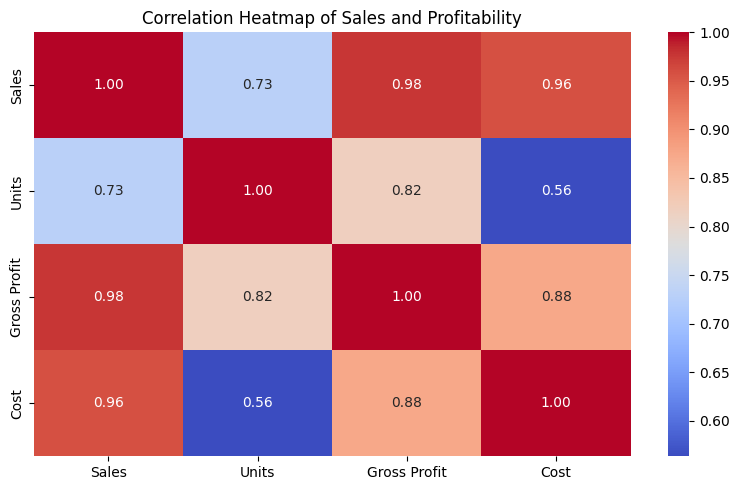

In [417]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_data = df[["Sales", "Units", "Gross Profit", "Cost"]]

plt.figure(figsize=(8, 5))
sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Sales and Profitability")
plt.tight_layout()
plt.show()

## 4. Product and Regional Profitability Analysis

In this section, we analyze gross profit across products, regions, and shipping modes to identify high-performing products, profitable regions, and differences in shipping performance. These findings help support business decisions about product focus and distribution.

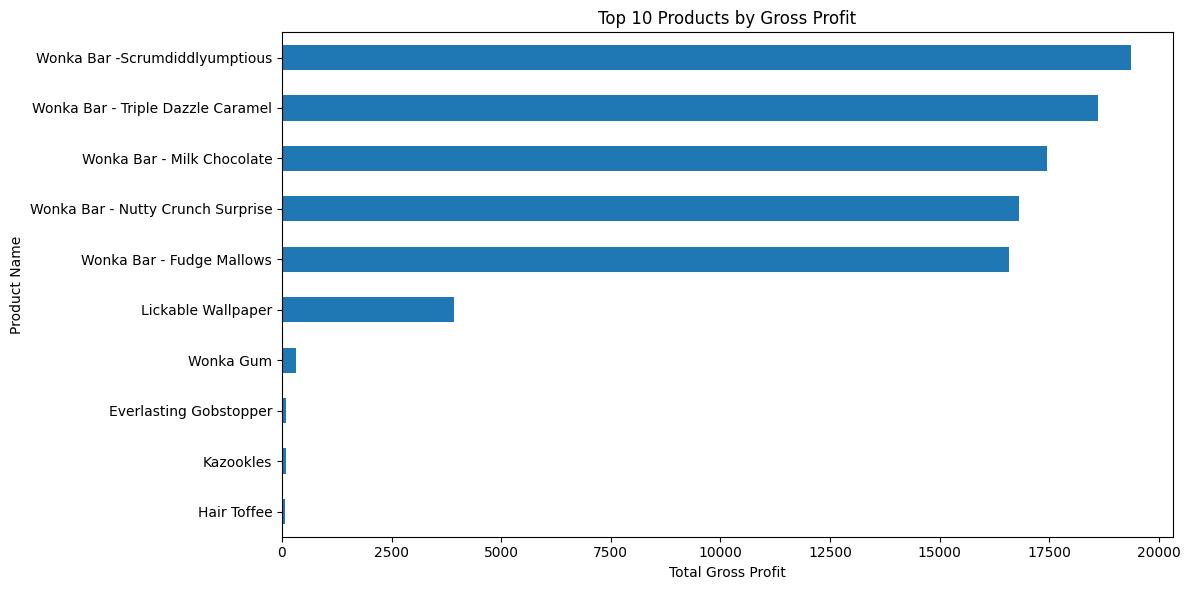

In [418]:

top_products = (
    df.groupby("Product Name")["Gross Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Gross Profit")
plt.xlabel("Total Gross Profit")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()


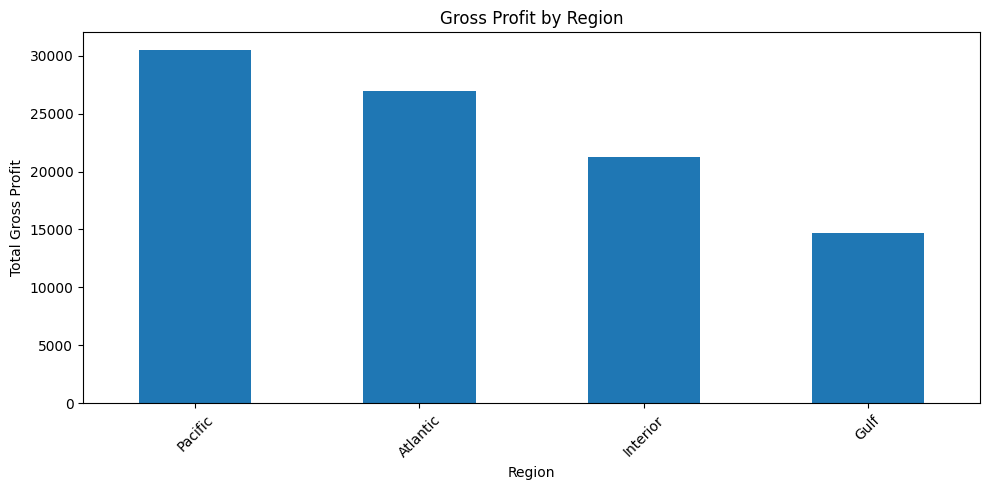

Region
Pacific     30485.94
Atlantic    26973.70
Interior    21282.49
Gulf        14700.67
Name: Gross Profit, dtype: float64


In [419]:

region_profit = (
    df.groupby("Region")["Gross Profit"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
region_profit.plot(kind="bar")
plt.title("Gross Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(region_profit)


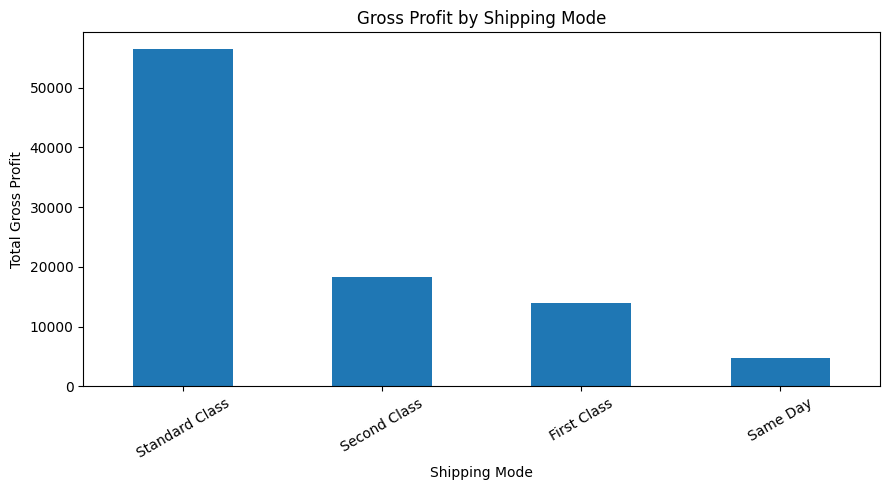

Ship Mode
Standard Class    56424.46
Second Class      18306.52
First Class       14011.09
Same Day           4700.73
Name: Gross Profit, dtype: float64


In [420]:

shipping_profit = (
    df.groupby("Ship Mode")["Gross Profit"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
shipping_profit.plot(kind="bar")
plt.title("Gross Profit by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print(shipping_profit)


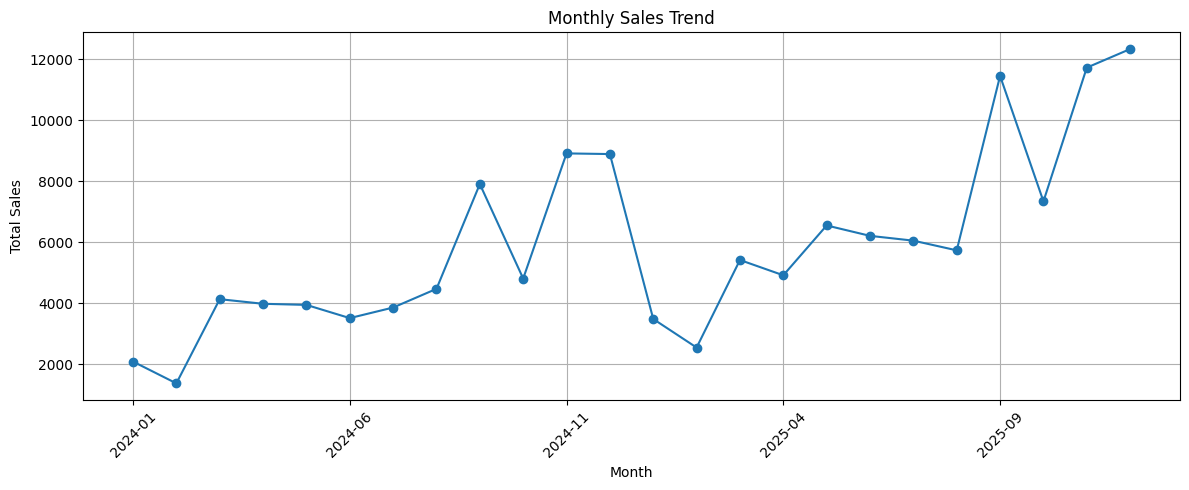

In [421]:

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y"
)

monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"]
    .sum()
)

plt.figure(figsize=(12, 5))
monthly_sales.index = monthly_sales.index.astype(str)
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


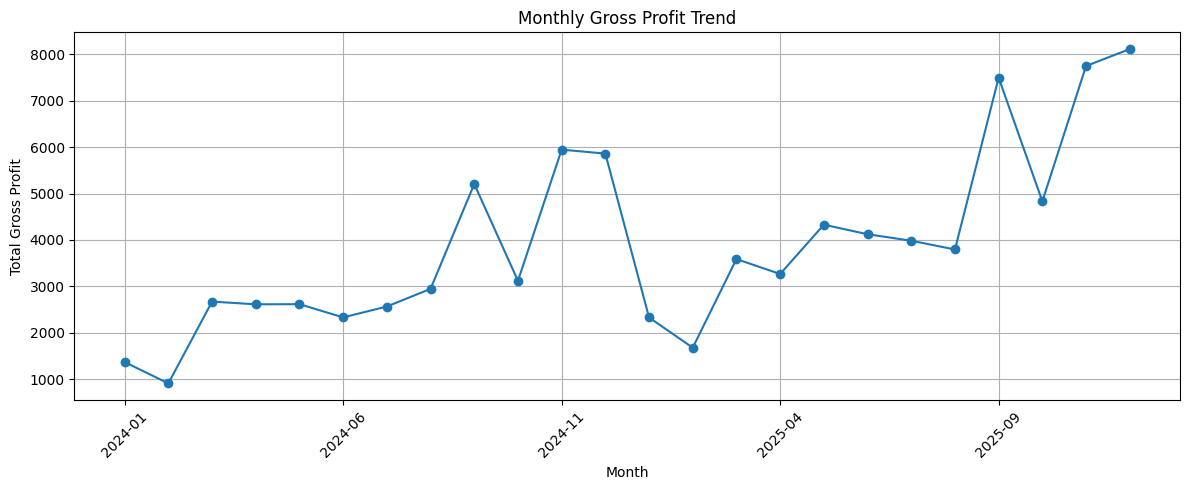

In [422]:

monthly_profit = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Gross Profit"]
    .sum()
)

plt.figure(figsize=(12, 5))
monthly_profit.index = monthly_profit.index.astype(str)
monthly_profit.plot(kind="line", marker="o")
plt.title("Monthly Gross Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


10 Lowest-Margin Products:
                                   Total_Sales  Total_Gross_Profit  \
Product Name                                                         
Kazookles                              1205.75               92.75   
Fun Dip                                  12.00                4.80   
Nerds                                    15.00                7.00   
SweeTARTS                                61.50               28.70   
Lickable Wallpaper                     7860.00             3930.00   
Wonka Gum                               597.50              310.70   
Fizzy Lifting Drinks                     78.75               47.25   
Laffy Taffy                              53.73               33.48   
Wonka Bar - Milk Chocolate            26867.75            17443.37   
Wonka Bar - Triple Dazzle Caramel     28485.00            18610.20   

                                   Total_Cost  Profit_Margin_%  
Product Name                                                    
Ka

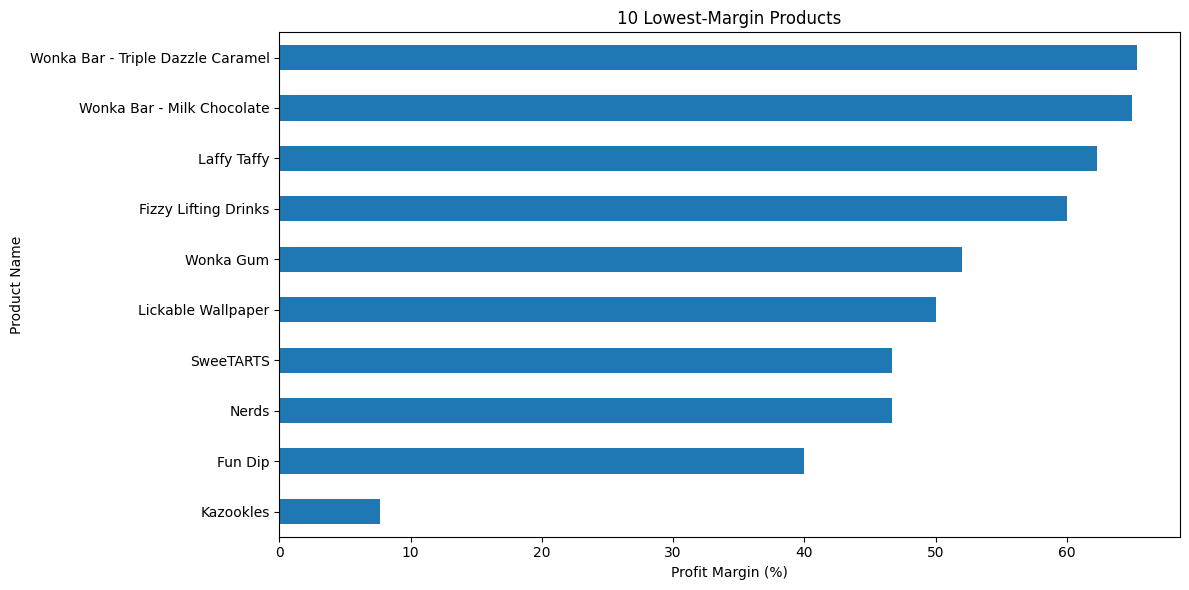

In [423]:

product_analysis = df.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Gross_Profit=("Gross Profit", "sum"),
    Total_Cost=("Cost", "sum")
)

product_analysis["Profit_Margin_%"] = (
    product_analysis["Total_Gross_Profit"]
    / product_analysis["Total_Sales"] * 100
)

low_margin = product_analysis[
    product_analysis["Total_Sales"] > 0
].sort_values("Profit_Margin_%").head(10)

print("10 Lowest-Margin Products:")
print(low_margin)

plt.figure(figsize=(12, 6))
low_margin["Profit_Margin_%"].sort_values().plot(kind="barh")
plt.title("10 Lowest-Margin Products")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()


In [424]:

total_sales = df["Sales"].sum()
total_cost = df["Cost"].sum()
total_profit = df["Gross Profit"].sum()
profit_margin = (total_profit / total_sales) * 100

print("===== BUSINESS PERFORMANCE KPIs =====")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Cost: ${total_cost:,.2f}")
print(f"Total Gross Profit: ${total_profit:,.2f}")
print(f"Overall Profit Margin: {profit_margin:.2f}%")


===== BUSINESS PERFORMANCE KPIs =====
Total Sales: $141,783.63
Total Cost: $48,340.83
Total Gross Profit: $93,442.80
Overall Profit Margin: 65.91%


Top 10 Customers by Gross Profit:
             Total_Sales  Total_Gross_Profit
Customer ID                                 
131807            454.40              256.60
115238            380.50              249.30
122336            352.20              193.44
164756            304.14              166.42
139675            202.00              134.40
151799            197.60              132.52
124163            247.35              127.95
100111            182.41              125.93
164770            232.40              122.50
119508            177.14              122.34


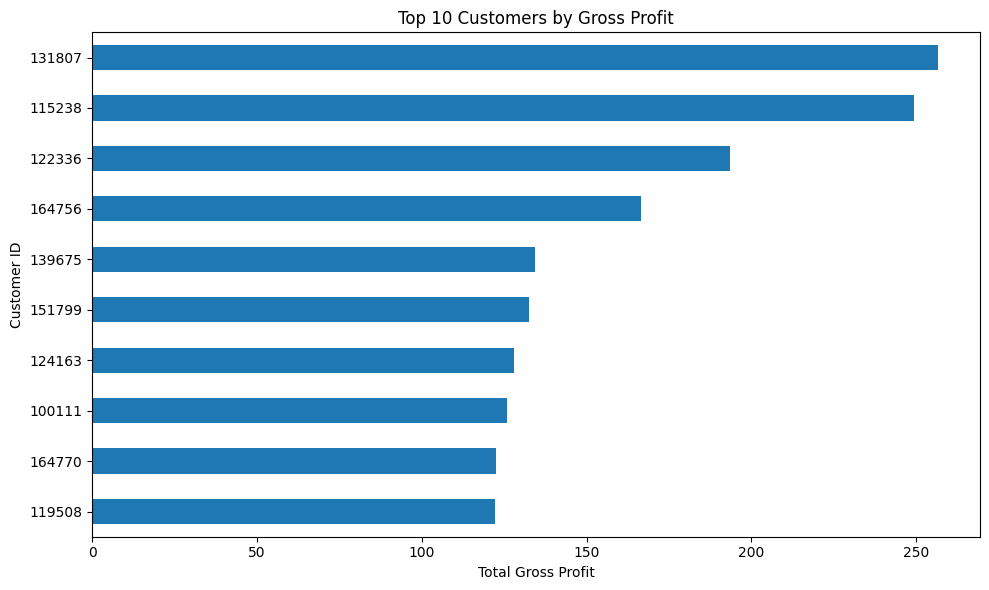

In [425]:

customer_profit = (
    df.groupby("Customer ID")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Gross_Profit=("Gross Profit", "sum")
    )
    .sort_values("Total_Gross_Profit", ascending=False)
)

top_customers = customer_profit.head(10)

print("Top 10 Customers by Gross Profit:")
print(top_customers)

plt.figure(figsize=(10, 6))
top_customers["Total_Gross_Profit"].sort_values().plot(kind="barh")
plt.title("Top 10 Customers by Gross Profit")
plt.xlabel("Total Gross Profit")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


Gross Profit by Division:
Division
Chocolate    88824.62
Other         4333.45
Sugar          284.73
Name: Gross Profit, dtype: float64


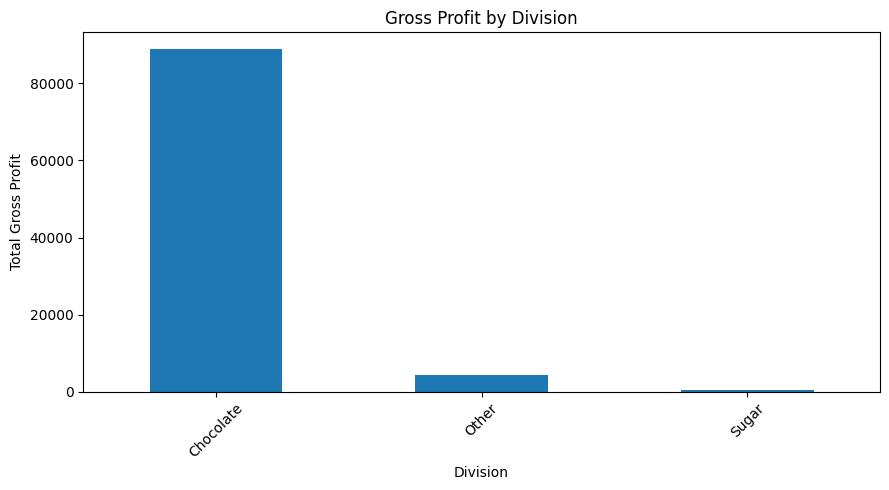

In [426]:

division_profit = (
    df.groupby("Division")["Gross Profit"]
    .sum()
    .sort_values(ascending=False)
)

print("Gross Profit by Division:")
print(division_profit)

plt.figure(figsize=(9, 5))
division_profit.plot(kind="bar")
plt.title("Gross Profit by Division")
plt.xlabel("Division")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## 5. Machine Learning Model Development

In this section, we prepare the dataset, train a machine learning model to predict gross profit, and evaluate its performance using suitable metrics.


In [448]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

X = df[["Product Name", "Units"]]
y = df["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("product", OneHotEncoder(handle_unknown="ignore"), ["Product Name"]),
        ("units", "passthrough", ["Units"])
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100, random_state=42
    ))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R² Score:", r2_score(y_test, predictions))


Mean Absolute Error: 0.02041113290830058
R² Score: 0.9967801635948943



### Random Forest Model Evaluation

The Random Forest Regressor was trained to predict Gross Profit using Product Name and Units.

- Mean Absolute Error (MAE): 0.0204
- R² Score: 0.9968

These are preliminary results from a random train-test split. Further validation is required before concluding that the model generalizes well to unseen products.


In [428]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

X = df[["Product Name", "Units"]]
y = df["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

preprocessor = ColumnTransformer([
    ("product", OneHotEncoder(handle_unknown="ignore"), ["Product Name"]),
    ("units", "passthrough", ["Units"])
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100, random_state=42
    ))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Mean Absolute Error (MAE):",
      mean_absolute_error(y_test, predictions))

print("R² Score:",
      r2_score(y_test, predictions))


Mean Absolute Error (MAE): 0.02041113290830058
R² Score: 0.9967801635948943


In [429]:

results = pd.DataFrame({
    "Actual Gross Profit": y_test.values,
    "Predicted Gross Profit": predictions
})

results["Prediction Error"] = (
    results["Actual Gross Profit"] -
    results["Predicted Gross Profit"]
)

print(results.head(10).round(2))


   Actual Gross Profit  Predicted Gross Profit  Prediction Error
0                 7.20                    7.20              -0.0
1                 2.45                    2.45               0.0
2                 7.35                    7.35               0.0
3                 9.60                    9.60              -0.0
4                 7.50                    7.50               0.0
5                19.20                   19.20              -0.0
6                21.60                   21.60               0.0
7                 7.50                    7.50               0.0
8                 4.98                    4.98              -0.0
9                 4.80                    4.80               0.0


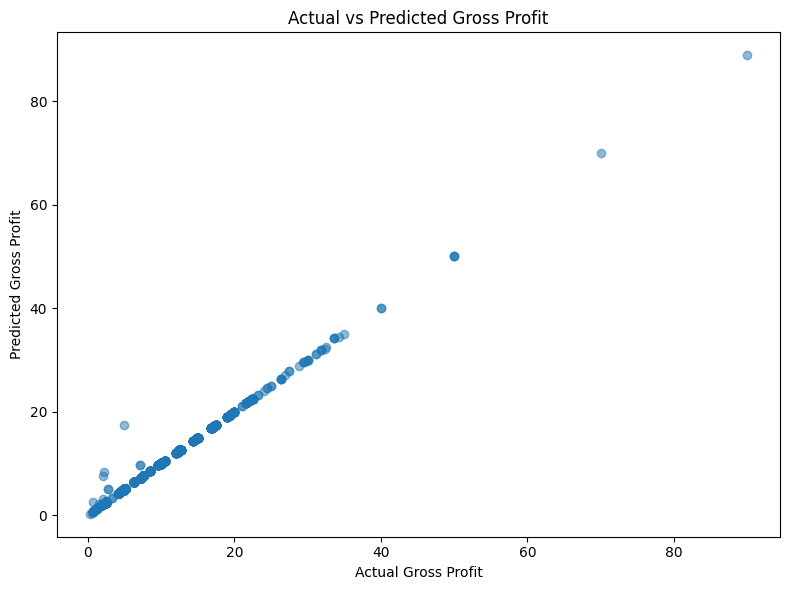

In [430]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.5)

plt.xlabel("Actual Gross Profit")
plt.ylabel("Predicted Gross Profit")
plt.title("Actual vs Predicted Gross Profit")

plt.tight_layout()
plt.show()


                                             Feature  Importance
15                                      units__Units    0.661742
6           product__Product Name_Lickable Wallpaper    0.289515
14                   product__Product Name_Wonka Gum    0.017046
4                    product__Product Name_Kazookles    0.015866
10  product__Product Name_Wonka Bar - Milk Chocolate    0.008163
0       product__Product Name_Everlasting Gobstopper    0.005213
8                    product__Product Name_SweeTARTS    0.000922
5                  product__Product Name_Laffy Taffy    0.000403
9    product__Product Name_Wonka Bar - Fudge Mallows    0.000356
2                      product__Product Name_Fun Dip    0.000234


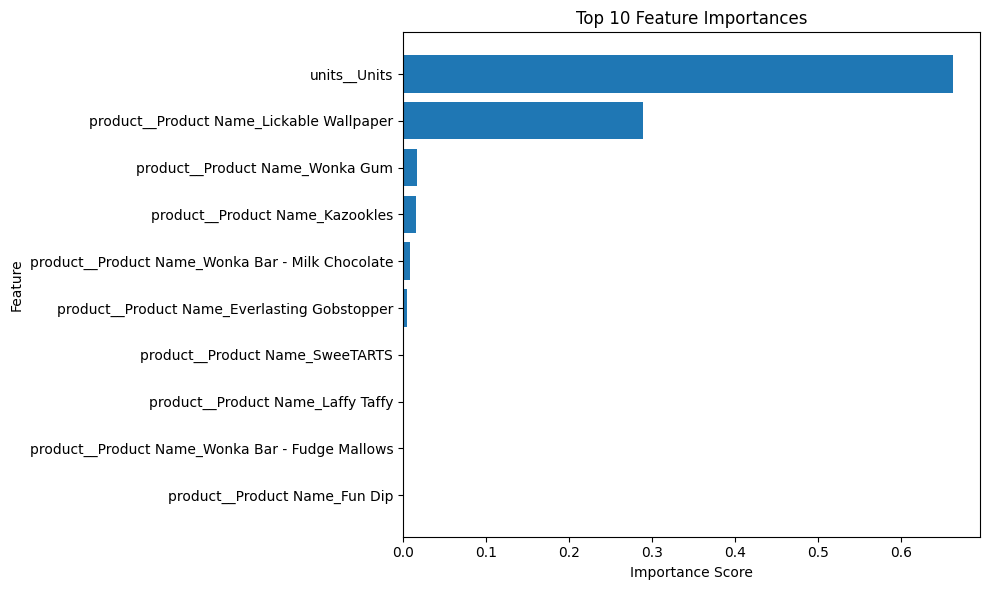

In [431]:

feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

print(importance_df.head(10))

top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()



## 6. Business Insights and Recommendations

### Key Insights
- Product profitability analysis helps identify products that contribute the most gross profit.
- Regional analysis compares gross profit across different regions.
- Shipping-mode analysis shows how total gross profit varies by shipping method.
- Monthly sales and gross profit trends help identify changes in business performance over time.
- Low-margin product analysis identifies products that may need pricing or cost improvements.
- Customer profitability analysis identifies customers contributing the most gross profit.

### Business Recommendations
- Focus on products that generate high gross profit while monitoring their costs.
- Investigate low-margin products to identify opportunities for pricing or cost optimization.
- Review regional performance to identify areas that may benefit from additional sales efforts.
- Monitor monthly sales and gross profit trends to support inventory and sales planning.
- Maintain relationships with profitable customers.
- Evaluate shipping costs and service quality before making changes to shipping methods.



## 7. Conclusion

This project analyzes the profitability and margin performance of Nassau Candy Distributor using Python, Pandas, Matplotlib, Seaborn, and Scikit-learn. It examines product, regional, shipping, customer, and monthly performance. A Random Forest regression model is also explored to predict gross profit using product name and units sold. The analysis provides insights that can support business decisions about product performance, pricing, and profitability.


In [432]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

X = df[["Units"]]
y = df["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_units = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model_units.fit(X_train, y_train)
y_pred_units = model_units.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, y_pred_units), 2))
print("R² Score:", round(r2_score(y_test, y_pred_units), 4))

MAE: 0.82
R² Score: 0.733


In [433]:
print("Model variables available:")

for name in ["model", "model_group", "model_better"]:
    if name in globals():
        print(name, "exists")

print("\nPrediction variables available:")

for name in ["predictions", "predictions_better"]:
    if name in globals():
        print(name, "exists")

Model variables available:
model exists
model_group exists
model_better exists

Prediction variables available:
predictions exists
predictions_better exists


In [434]:
print(df.shape)
print(df.columns.tolist())

(10194, 18)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost']


In [435]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

data = df[["Product Name", "Units", "Gross Profit"]].dropna().copy()

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

train_idx, test_idx = next(
    splitter.split(data, groups=data["Product Name"])
)

train = data.iloc[train_idx]
test = data.iloc[test_idx]

preprocessor = ColumnTransformer([
    ("product", OneHotEncoder(handle_unknown="ignore"),
     ["Product Name"]),
    ("units", "passthrough", ["Units"])
])

model_better = make_pipeline(
    preprocessor,
    RandomForestRegressor(n_estimators=100, random_state=42)
)

X_train = train[["Product Name", "Units"]]
X_test = test[["Product Name", "Units"]]

model_better.fit(X_train, train["Gross Profit"])
predictions_better = model_better.predict(X_test)

print("Random Forest MAE:",
      round(mean_absolute_error(
          test["Gross Profit"], predictions_better), 2))
print("Random Forest R²:",
      round(r2_score(
          test["Gross Profit"], predictions_better), 4))

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train[["Units"]], train["Gross Profit"])
baseline_predictions = baseline.predict(X_test[["Units"]])

print("Baseline MAE:",
      round(mean_absolute_error(
          test["Gross Profit"], baseline_predictions), 2))
print("Baseline R²:",
      round(r2_score(
          test["Gross Profit"], baseline_predictions), 4))

print("Training products:", train["Product Name"].nunique())
print("Testing products:", test["Product Name"].nunique())
print("Overlapping products:", len(
    set(train["Product Name"]) & set(test["Product Name"])))


Random Forest MAE: 0.22
Random Forest R²: 0.9794
Baseline MAE: 4.19
Baseline R²: -0.0003
Training products: 12
Testing products: 3
Overlapping products: 0


In [436]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

data = df[["Product Name", "Units", "Gross Profit"]].dropna().copy()

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

train_idx, test_idx = next(
    splitter.split(data, groups=data["Product Name"])
)

train = data.iloc[train_idx]
test = data.iloc[test_idx]

X_train = pd.DataFrame({
    "Units": train["Units"],
    "ProductCode": train["Product Name"].astype("category").cat.codes
})

X_test = pd.DataFrame({
    "Units": test["Units"],
    "ProductCode": test["Product Name"].astype("category").cat.codes
})

model_group = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model_group.fit(X_train[["Units"]], train["Gross Profit"])
predictions = model_group.predict(X_test[["Units"]])

print("Test rows:", len(test))
print("MAE:", round(mean_absolute_error(test["Gross Profit"], predictions), 2))
print("R² Score:", round(r2_score(test["Gross Profit"], predictions), 4))

Test rows: 3631
MAE: 0.27
R² Score: 0.9746


In [437]:
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train[["Units"]], train["Gross Profit"])

baseline_predictions = baseline.predict(X_test[["Units"]])

print("Baseline MAE:",
      round(mean_absolute_error(test["Gross Profit"], baseline_predictions), 2))

print("Baseline R² Score:",
      round(r2_score(test["Gross Profit"], baseline_predictions), 4))

Baseline MAE: 4.19
Baseline R² Score: -0.0003


In [438]:
print("Training products:", train["Product Name"].nunique())
print("Testing products:", test["Product Name"].nunique())

print("Overlapping products:",
      len(set(train["Product Name"]) & set(test["Product Name"])))

Training products: 12
Testing products: 3
Overlapping products: 0


In [439]:
print("Units-only predictions:", predictions[:5])
print("Improved model predictions:", predictions_better[:5])

print("Improved model features:")
print(model_better.named_steps["columntransformer"].get_feature_names_out())

Units-only predictions: [ 7.15486856  4.79365749  4.79365749 14.34435562 12.0984856 ]
Improved model predictions: [ 7.1265  4.804   4.804  14.88   11.98  ]
Improved model features:
['product__Product Name_Fizzy Lifting Drinks'
 'product__Product Name_Fun Dip' 'product__Product Name_Hair Toffee'
 'product__Product Name_Kazookles' 'product__Product Name_Laffy Taffy'
 'product__Product Name_Lickable Wallpaper' 'product__Product Name_Nerds'
 'product__Product Name_SweeTARTS'
 'product__Product Name_Wonka Bar - Milk Chocolate'
 'product__Product Name_Wonka Bar - Triple Dazzle Caramel'
 'product__Product Name_Wonka Bar -Scrumdiddlyumptious'
 'product__Product Name_Wonka Gum' 'units__Units']


In [440]:
comparison = test[["Product Name", "Units", "Gross Profit"]].copy()

comparison["Predicted Gross Profit"] = predictions

comparison["Absolute Error"] = abs(
    comparison["Gross Profit"] -
    comparison["Predicted Gross Profit"]
)

print(comparison.head(15).to_string(index=False))

                     Product Name  Units  Gross Profit  Predicted Gross Profit  Absolute Error
Wonka Bar - Nutty Crunch Surprise      3          7.47                7.154869        0.315131
Wonka Bar - Nutty Crunch Surprise      2          4.98                4.793657        0.186343
        Wonka Bar - Fudge Mallows      2          4.80                4.793657        0.006343
Wonka Bar - Nutty Crunch Surprise      6         14.94               14.344356        0.595644
Wonka Bar - Nutty Crunch Surprise      5         12.45               12.098486        0.351514
        Wonka Bar - Fudge Mallows      2          4.80                4.793657        0.006343
Wonka Bar - Nutty Crunch Surprise      4          9.96                9.627276        0.332724
        Wonka Bar - Fudge Mallows     10         24.00               26.514875        2.514875
        Wonka Bar - Fudge Mallows      4          9.60                9.627276        0.027276
        Wonka Bar - Fudge Mallows      3          

In [441]:
print("Units-only predictions:")
print(predictions[:5])

print("\nImproved model predictions:")
print(predictions_better[:5])

print("\nImproved model features:")
print(model_better.named_steps["columntransformer"].get_feature_names_out())

Units-only predictions:
[ 7.15486856  4.79365749  4.79365749 14.34435562 12.0984856 ]

Improved model predictions:
[ 7.1265  4.804   4.804  14.88   11.98  ]

Improved model features:
['product__Product Name_Fizzy Lifting Drinks'
 'product__Product Name_Fun Dip' 'product__Product Name_Hair Toffee'
 'product__Product Name_Kazookles' 'product__Product Name_Laffy Taffy'
 'product__Product Name_Lickable Wallpaper' 'product__Product Name_Nerds'
 'product__Product Name_SweeTARTS'
 'product__Product Name_Wonka Bar - Milk Chocolate'
 'product__Product Name_Wonka Bar - Triple Dazzle Caramel'
 'product__Product Name_Wonka Bar -Scrumdiddlyumptious'
 'product__Product Name_Wonka Gum' 'units__Units']


In [442]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

data = df[["Product Name", "Units", "Gross Profit"]].dropna().copy()

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

train_idx, test_idx = next(
    splitter.split(data, groups=data["Product Name"])
)

train = data.iloc[train_idx]
test = data.iloc[test_idx]

preprocessor = ColumnTransformer([
    ("product", OneHotEncoder(handle_unknown="ignore"),
     ["Product Name"]),
    ("units", "passthrough", ["Units"])
])

model_better = make_pipeline(
    preprocessor,
    RandomForestRegressor(n_estimators=100, random_state=42)
)

model_better.fit(
    train[["Product Name", "Units"]],
    train["Gross Profit"]
)

predictions_better = model_better.predict(
    test[["Product Name", "Units"]]
)

print("MAE:", round(
    mean_absolute_error(test["Gross Profit"], predictions_better), 2
))
print("R² Score:", round(
    r2_score(test["Gross Profit"], predictions_better), 4
))


MAE: 0.22
R² Score: 0.9794


In [443]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

baseline_better = DummyRegressor(strategy="mean")

baseline_better.fit(
    train[["Units"]],
    train["Gross Profit"]
)

baseline_predictions_better = baseline_better.predict(
    test[["Units"]]
)

print("Baseline MAE:", round(
    mean_absolute_error(test["Gross Profit"],
                        baseline_predictions_better), 2
))

print("Baseline R² Score:", round(
    r2_score(test["Gross Profit"],
             baseline_predictions_better), 4
))


Baseline MAE: 4.19
Baseline R² Score: -0.0003


In [444]:
comparison_better = test[
    ["Product Name", "Units", "Gross Profit"]
].copy()

comparison_better["Predicted Gross Profit"] = predictions_better

comparison_better["Absolute Error"] = abs(
    comparison_better["Gross Profit"]
    - comparison_better["Predicted Gross Profit"]
)

print(comparison_better.head(15).to_string(index=False))

                     Product Name  Units  Gross Profit  Predicted Gross Profit  Absolute Error
Wonka Bar - Nutty Crunch Surprise      3          7.47                  7.1265          0.3435
Wonka Bar - Nutty Crunch Surprise      2          4.98                  4.8040          0.1760
        Wonka Bar - Fudge Mallows      2          4.80                  4.8040          0.0040
Wonka Bar - Nutty Crunch Surprise      6         14.94                 14.8800          0.0600
Wonka Bar - Nutty Crunch Surprise      5         12.45                 11.9800          0.4700
        Wonka Bar - Fudge Mallows      2          4.80                  4.8040          0.0040
Wonka Bar - Nutty Crunch Surprise      4          9.96                  9.5020          0.4580
        Wonka Bar - Fudge Mallows     10         24.00                 24.7900          0.7900
        Wonka Bar - Fudge Mallows      4          9.60                  9.5020          0.0980
        Wonka Bar - Fudge Mallows      3          

In [445]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

X = df[["Product Name", "Units"]].copy()
X["Product Name"] = X["Product Name"].astype("category").cat.codes
y = df["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_product = RandomForestRegressor(
    n_estimators=100, random_state=42
)
model_product.fit(X_train, y_train)

y_pred_product = model_product.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, y_pred_product), 2))
print("R² Score:", round(r2_score(y_test, y_pred_product), 4))

MAE: 0.03
R² Score: 0.9913


In [446]:
print(df[["Sales", "Cost", "Gross Profit"]].head(10))

print("\nCheck whether Sales - Cost equals Gross Profit:")
print(
    (df["Sales"] - df["Cost"] - df["Gross Profit"])
    .abs()
    .describe()
)

   Sales  Cost  Gross Profit
0   6.50  2.28          4.22
1   7.50  2.60          4.90
2  10.47  3.00          7.47
3  10.80  3.30          7.50
4  11.25  3.90          7.35
5  32.40  9.90         22.50
6   7.50  2.60          4.90
7   9.75  3.42          6.33
8   6.98  2.00          4.98
9  13.00  4.56          8.44

Check whether Sales - Cost equals Gross Profit:
count    1.019400e+04
mean     4.771759e-16
std      8.033726e-16
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      8.881784e-16
max      7.105427e-15
dtype: float64


In [447]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("R² Score:", round(r2, 4))

NameError: name 'y_pred' is not defined

In [ ]:
X = df[["Sales", "Units", "Cost"]]
y = df["Gross Profit"]

In [ ]:
print("Model:", type(model).__name__)
print("Test data rows:", len(X_test))
print("Predictions:", len(y_pred))

In [ ]:
import os

print("Saved model exists:",
      os.path.exists("/content/profit_prediction_model.pkl"))

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

features = ["Sales", "Units", "Cost"]

ml_data = df[features + ["Gross Profit"]].copy()
ml_data = ml_data.apply(pd.to_numeric, errors="coerce")
ml_data = ml_data.dropna()

X = ml_data[features]
y = ml_data["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R² Score:", r2_score(y_test, predictions))

In [ ]:
print(type(model).__name__)

In [ ]:
!pkill -f "streamlit run app.py" || true

In [ ]:
!streamlit run app.py --server.port 8502 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false --browser.gatherUsageStats false > /content/streamlit2.log 2>&1 &

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8502)

In [ ]:
y_pred = model.predict(X_test)

print("Predictions created successfully!")
print("Number of predictions:", len(y_pred))

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("R² Score:", round(r2, 4))

In [ ]:
import os

for file in ["app.py", "profit_prediction_model.pkl",
             "Nassau Candy Distributor.csv"]:
    print(file, "->", os.path.exists("/content/" + file))

In [ ]:
import os

print("Project files:")
for file in os.listdir("/content"):
    if file.endswith((".py", ".csv", ".pkl", ".ipynb", ".md", ".txt")):
        print(file)

In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8502)

In [ ]:
!cat /content/streamlit2.log

In [ ]:
!ps aux | grep '[s]treamlit run'

In [ ]:
from google.colab import output
output.serve_kernel_port_as_window(8502)

In [ ]:
!cat /content/streamlit2.log

In [ ]:
!streamlit run app.py --server.port 8502 --server.address 0.0.0.0 > /content/streamlit2.log 2>&1 &

In [ ]:
!cat /content/streamlit.log

In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 &>/content/streamlit.log &

In [ ]:
!cat /content/streamlit.log

In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 &>/content/streamlit.log &

In [ ]:
import os
print(os.path.exists("app.py"))

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd

st.set_page_config(
    page_title="Nassau Candy Profitability",
    layout="wide"
)

st.title("Nassau Candy Distributor")
st.subheader("Product Line Profitability & Margin Performance")

df = pd.read_csv("Nassau Candy Distributor.csv")

total_sales = df["Sales"].sum()
total_profit = df["Gross Profit"].sum()
total_cost = df["Cost"].sum()
margin = total_profit / total_sales * 100 if total_sales else 0

c1, c2, c3, c4 = st.columns(4)

c1.metric("Total Sales", f"${total_sales:,.2f}")
c2.metric("Gross Profit", f"${total_profit:,.2f}")
c3.metric("Total Cost", f"${total_cost:,.2f}")
c4.metric("Profit Margin", f"{margin:.2f}%")

df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

monthly = (
    df.dropna(subset=["Order Date"])
    .assign(Month=lambda x: x["Order Date"].dt.to_period("M").astype(str))
    .groupby("Month")[["Sales", "Gross Profit"]]
    .sum()
)

st.subheader("Monthly Sales and Gross Profit")
st.line_chart(monthly)

st.subheader("Top 10 Products by Gross Profit")
products = (
    df.groupby("Product Name")["Gross Profit"]
    .sum()
    .nlargest(10)
    .sort_values()
)
st.bar_chart(products)

In [ ]:
!cat /content/streamlit.log

In [ ]:
import os

print("Dataset available:", os.path.exists("Nassau Candy Distributor.csv"))
print("Model available:", os.path.exists("profit_prediction_model.pkl"))

In [ ]:
!pip install streamlit

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

features = ["Sales", "Units", "Cost"]

ml_data = df[features + ["Gross Profit"]].copy()
ml_data = ml_data.apply(pd.to_numeric, errors="coerce")
ml_data = ml_data.dropna()

X = ml_data[features]
y = ml_data["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R² Score:", r2_score(y_test, predictions))

In [ ]:
import joblib

joblib.dump(model, "profit_prediction_model.pkl")

print("Model saved successfully!")

In [ ]:
print("MAE:", mean_absolute_error(y_test, predictions))
print("R2 Score:", r2_score(y_test, predictions))

print("\nActual vs Predicted Sample:")
comparison = pd.DataFrame({
    "Actual Gross Profit": y_test.iloc[:10].values,
    "Predicted Gross Profit": predictions[:10]
})

display(comparison)

In [ ]:
product_data = df.groupby(
    ["Product ID", "Product Name"], as_index=False
).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum"
})

product_data["Profit Margin (%)"] = (
    product_data["Gross Profit"] /
    product_data["Sales"].replace(0, float("nan")) * 100
)

low_margin = product_data[
    product_data["Sales"] > 0
].sort_values("Profit Margin (%)").head(10)

print("10 Lowest-Margin Products")
print(low_margin.to_string(index=False))

In [ ]:
print("===== BUSINESS INSIGHTS =====")

best_product = product_data.loc[
    product_data["Gross Profit"].idxmax()
]
print("\nMost Profitable Product:")
print(best_product[["Product Name", "Sales", "Gross Profit"]])

best_region = df.groupby("Region")["Gross Profit"].sum().idxmax()
region_profit = df.groupby("Region")["Gross Profit"].sum().max()
print("\nMost Profitable Region:", best_region)
print("Regional Gross Profit:", round(region_profit, 2))

best_division = df.groupby("Division")["Gross Profit"].sum().idxmax()
division_profit = df.groupby("Division")["Gross Profit"].sum().max()
print("\nMost Profitable Division:", best_division)
print("Division Gross Profit:", round(division_profit, 2))

print("\nOverall Profit Margin (%):",
      round(df["Gross Profit"].sum() / df["Sales"].sum() * 100, 2))

In [ ]:
print("MAE:", mean_absolute_error(y_test, predictions))
print("R2 Score:", r2_score(y_test, predictions))

print("\nActual vs Predicted Sample:")
comparison = pd.DataFrame({
    "Actual Gross Profit": y_test.iloc[:10].values,
    "Predicted Gross Profit": predictions[:10]
})

display(comparison)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(y_test, predictions)

plt.xlabel("Actual Gross Profit")
plt.ylabel("Predicted Gross Profit")
plt.title("Actual vs Predicted Gross Profit")

minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    "Importance", ascending=False
)

print(importance)

plt.figure(figsize=(8, 5))
plt.bar(importance["Feature"], importance["Importance"])
plt.title("Feature Importance for Gross Profit Prediction")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

features = ["Sales", "Units", "Cost"]

ml_data = df[features + ["Gross Profit"]].copy()
ml_data = ml_data.apply(pd.to_numeric, errors="coerce")
ml_data = ml_data.dropna()

X = ml_data[features]
y = ml_data["Gross Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R² Score:", r2_score(y_test, predictions))

In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSample data:")
display(df.head())

In [ ]:
division_data = df.groupby("Division", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum",
    "Order ID": "nunique"
})

division_data = division_data.rename(
    columns={"Order ID": "Total Orders"}
)

division_data["Profit Margin (%)"] = (
    division_data["Gross Profit"] /
    division_data["Sales"].replace(0, float("nan")) * 100
)

print(division_data.sort_values(
    "Gross Profit", ascending=False
).to_string(index=False))

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(division_data["Division"], division_data["Gross Profit"])
plt.title("Gross Profit by Division")
plt.xlabel("Division")
plt.ylabel("Gross Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt

customer_data = df.groupby("Customer ID", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Order ID": "nunique"
})

customer_data = customer_data.rename(
    columns={"Order ID": "Total Orders"}
)

customer_data["Profit Margin (%)"] = (
    customer_data["Gross Profit"] /
    customer_data["Sales"].replace(0, float("nan")) * 100
)

top_customers = customer_data.nlargest(10, "Gross Profit")

print("Top 10 Customers by Gross Profit")
print(top_customers.to_string(index=False))

plt.figure(figsize=(12, 6))
plt.bar(
    top_customers["Customer ID"].astype(str),
    top_customers["Gross Profit"]
)
plt.title("Top 10 Customers by Gross Profit")
plt.xlabel("Customer ID")
plt.ylabel("Gross Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
product_data = df.groupby(
    ["Product ID", "Product Name"], as_index=False
).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum"
})

product_data["Profit Margin (%)"] = (
    product_data["Gross Profit"] /
    product_data["Sales"].replace(0, float("nan")) * 100
)

low_margin = product_data[
    product_data["Sales"] > 0
].sort_values("Profit Margin (%)").head(10)

print("10 Lowest-Margin Products")
print(low_margin.to_string(index=False))

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.barh(
    low_margin["Product Name"],
    low_margin["Profit Margin (%)"]
)
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product")
plt.title("10 Lowest-Margin Products")
plt.tight_layout()
plt.show()

In [ ]:
total_sales = df["Sales"].sum()
total_profit = df["Gross Profit"].sum()
total_cost = df["Cost"].sum()
total_units = df["Units"].sum()
total_orders = df["Order ID"].nunique()

profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else 0
)

print("Total Sales:", round(total_sales, 2))
print("Total Gross Profit:", round(total_profit, 2))
print("Total Cost:", round(total_cost, 2))
print("Total Units Sold:", total_units)
print("Total Orders:", total_orders)
print("Overall Profit Margin (%):", round(profit_margin, 2))

In [ ]:
df.columns = df.columns.str.strip()
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Gross Profit"] = pd.to_numeric(df["Gross Profit"], errors="coerce")

temp = df.dropna(subset=["Order Date"]).copy()
temp["Month"] = temp["Order Date"].dt.to_period("M").astype(str)

monthly_data = temp.groupby("Month", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum"
})

print(monthly_data.head())

In [ ]:
print(monthly_data.columns.tolist())
print(monthly_data.head())

In [ ]:
df.columns = df.columns.str.strip()
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Gross Profit"] = pd.to_numeric(df["Gross Profit"], errors="coerce")

temp = df.dropna(subset=["Order Date"]).copy()
temp["Month"] = temp["Order Date"].dt.to_period("M").astype(str)

monthly_data = temp.groupby("Month", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum"
})

print(monthly_data.head())

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Clean column names
df.columns = df.columns.str.strip()

# Convert Order Date into datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

# Create monthly data
df = df.dropna(subset=["Order Date"])
df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

# Ensure numeric values
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

if "Gross Profit" in df.columns:
    df["Gross Profit"] = pd.to_numeric(
        df["Gross Profit"], errors="coerce"
    )
    monthly_data = df.groupby("Month", as_index=False)[
        ["Sales", "Gross Profit"]
    ].sum()
else:
    monthly_data = df.groupby("Month", as_index=False)[
        ["Sales"]
    ].sum()

# Plot graph
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_data["Month"],
    monthly_data["Sales"],
    marker="o",
    label="Sales"
)

if "Gross Profit" in monthly_data.columns:
    plt.plot(
        monthly_data["Month"],
        monthly_data["Gross Profit"],
        marker="o",
        label="Gross Profit"
    )

plt.xlabel("Month")
plt.ylabel("Amount")
plt.title("Monthly Sales and Gross Profit")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
print(df.columns.tolist())
print(monthly_data.columns.tolist())
print(monthly_data.head())

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

temp = df.dropna(subset=["Order Date"]).copy()
temp["Month"] = temp["Order Date"].dt.to_period("M")

monthly_data = temp.groupby("Month")[["Sales", "Gross Profit"]].sum()

ax = monthly_data.plot(figsize=(12, 5), marker="o")

ax.set_title("Monthly Sales and Gross Profit Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Amount")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

print("df exists:", "df" in globals())
print("monthly_data exists:", "monthly_data" in globals())


In [ ]:
print(monthly_data.columns.tolist())

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df["Month"] = df["Order Date"].dt.to_period("M")

monthly_data = df.groupby("Month").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

monthly_data["Month"] = monthly_data["Month"].astype(str)

print(monthly_data.head())

plt.figure(figsize=(12, 5))
plt.plot(monthly_data["Month"], monthly_data["Sales"], marker="o", label="Sales")
plt.plot(monthly_data["Month"], monthly_data["Gross Profit"], marker="o", label="Gross Profit")

plt.title("Monthly Sales and Gross Profit Trend")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df["Order Date"] = pd.to_datetime(df["Order Date"])

df["Month"] = df["Order Date"].dt.to_period("M")

monthly_data = df.groupby("Month").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

monthly_data["Month"] = monthly_data["Month"].astype(str)

print(monthly_data.head())


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

df["Month"] = df["Order Date"].dt.to_period("M")

monthly_data = df.groupby("Month", observed=True).agg(
    Sales=("Sales", "sum"),
    Gross_Profit=("Gross Profit", "sum"),
    Cost=("Cost", "sum")
).reset_index()

monthly_data["Month"] = monthly_data["Month"].astype(str)

print(monthly_data.head())


In [ ]:

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDate range:")
print("Start:", df["Order Date"].min())
print("End:", df["Order Date"].max())

print("\nSales:", round(df["Sales"].sum(), 2))
print("Cost:", round(df["Cost"].sum(), 2))
print("Gross Profit:", round(df["Gross Profit"].sum(), 2))


In [ ]:

total_sales = df["Sales"].sum()
total_cost = df["Cost"].sum()
total_profit = df["Gross Profit"].sum()
total_orders = df["Order ID"].nunique()
total_products = df["Product Name"].nunique()
total_units = df["Units"].sum()

profit_margin = (
    total_profit / total_sales * 100 if total_sales != 0 else 0
)

print("Total Sales:", round(total_sales, 2))
print("Total Cost:", round(total_cost, 2))
print("Total Gross Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Products:", total_products)
print("Total Units Sold:", total_units)
print("Overall Profit Margin:", round(profit_margin, 2), "%")


In [ ]:
print("Dataset columns:")
for col in df.columns:
    print(col)

In [ ]:

print("Dataset shape:", df.shape)

for col in df.columns:
    if any(word in col.lower() for word in
           ["factory", "latitude", "longitude", "product", "city", "state", "region"]):
        print(f"\n{col}")
        print(df[col].nunique(), "unique values")
        print(df[col].dropna().unique()[:10])


In [ ]:

# Create product analysis
df.columns = df.columns.str.strip()

product_analysis = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

product_analysis["Profit Margin (%)"] = (
    product_analysis["Gross Profit"] /
    product_analysis["Sales"].replace(0, float("nan"))
) * 100

print("Product analysis created successfully!")
display(product_analysis.head())


In [ ]:

top_products = product_analysis.sort_values(
    by="Gross Profit",
    ascending=False
)

display(top_products.head(10))


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df.columns = df.columns.str.strip()
df["Order Date"] = pd.to_datetime(
    df["Order Date"], dayfirst=True, errors="coerce"
)

for col in ["Sales", "Gross Profit", "Cost"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

temp = df.dropna(subset=["Order Date"]).copy()
temp["Month"] = temp["Order Date"].dt.to_period("M").astype(str)

monthly_data = temp.groupby("Month", as_index=False).agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
})

print(monthly_data.columns.tolist())
print(monthly_data.head())

plt.figure(figsize=(12, 5))
plt.plot(monthly_data["Month"], monthly_data["Sales"],
         marker="o", label="Sales")
plt.plot(monthly_data["Month"], monthly_data["Gross Profit"],
         marker="o", label="Gross Profit")

plt.title("Monthly Sales and Gross Profit Trend")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
for col in df.columns:
    if any(word in col.lower() for word in
           ["factory", "latitude", "longitude", "product", "location"]):
        print(col, ":", df[col].nunique(), "unique values")

In [ ]:
print("Top 10 Products")
display(top_products.head(10))

print("Bottom 10 Products")
display(product_analysis.sort_values(
    by="Gross Profit",
    ascending=True
).head(10))

In [ ]:

numerical_data = df[
    ["Sales", "Units", "Gross Profit", "Cost"]
]

correlation = numerical_data.corr()

display(correlation)


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Sales, Units, Cost and Gross Profit")
plt.tight_layout()
plt.show()


In [ ]:

shipping_analysis = df.groupby("Ship Mode").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Order ID": "nunique"
}).reset_index()

shipping_analysis = shipping_analysis.rename(
    columns={"Order ID": "Number of Orders"}
)

shipping_analysis["Profit Margin (%)"] = (
    shipping_analysis["Gross Profit"] /
    shipping_analysis["Sales"]
) * 100

display(shipping_analysis)


In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(
    shipping_analysis["Ship Mode"],
    shipping_analysis["Gross Profit"]
)
plt.xlabel("Shipping Mode")
plt.ylabel("Total Gross Profit")
plt.title("Gross Profit by Shipping Mode")
plt.tight_layout()
plt.show()


In [ ]:

region_analysis = df.groupby("Region").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

region_analysis["Profit Margin (%)"] = (
    region_analysis["Gross Profit"] /
    region_analysis["Sales"]
) * 100

region_analysis = region_analysis.sort_values(
    by="Gross Profit", ascending=False
)

display(region_analysis)


In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(region_analysis["Region"], region_analysis["Gross Profit"])
plt.xlabel("Region")
plt.ylabel("Total Gross Profit")
plt.title("Regional Profitability Analysis")
plt.tight_layout()
plt.show()


In [ ]:

df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)

df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("Month")["Sales"].sum().reset_index()

display(monthly_sales)


In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["Month"], monthly_sales["Sales"], marker="o")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.title("Monthly Sales Trend")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# Create division analysis
df.columns = df.columns.str.strip()

division_analysis = df.groupby("Division", as_index=False).agg({
    "Gross Profit": "sum"
})

display(division_analysis)


In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(
    division_analysis["Division"],
    division_analysis["Gross Profit"]
)
plt.xlabel("Division")
plt.ylabel("Total Gross Profit")
plt.title("Profitability Analysis by Division")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

division_analysis = df.groupby("Division").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

division_analysis["Profit Margin (%)"] = (
    division_analysis["Gross Profit"] /
    division_analysis["Sales"]
) * 100

division_analysis = division_analysis.sort_values(
    by="Gross Profit", ascending=False
)

display(division_analysis)


In [ ]:

product_analysis = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

product_analysis["Profit Margin (%)"] = (
    product_analysis["Gross Profit"] / product_analysis["Sales"]
) * 100

print("Product analysis created successfully!")
display(product_analysis.head())


In [ ]:

product_margin = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

product_margin["Profit Margin (%)"] = (
    product_margin["Gross Profit"] / product_margin["Sales"]
) * 100

product_margin = product_margin.sort_values(
    by="Profit Margin (%)", ascending=True
)

product_margin.head(10)


In [ ]:

top_products = df.groupby("Product Name")["Gross Profit"].sum().sort_values(ascending=False).reset_index()

top_products.head(10)


In [ ]:

import matplotlib.pyplot as plt

top10 = top_products.head(10)

plt.figure(figsize=(12, 6))
plt.bar(top10["Product Name"], top10["Gross Profit"])
plt.xticks(rotation=75, ha="right")
plt.xlabel("Product Name")
plt.ylabel("Total Gross Profit")
plt.title("Top 10 Products by Gross Profit")
plt.tight_layout()
plt.show()


In [ ]:

region_analysis = df.groupby("Region").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum"
}).reset_index()

region_analysis["Profit Margin (%)"] = (
    region_analysis["Gross Profit"] /
    region_analysis["Sales"]
) * 100

display(region_analysis)


In [ ]:

import matplotlib.pyplot as plt

top10 = top_products.head(10)

plt.figure(figsize=(12, 6))
plt.bar(top10["Product Name"], top10["Gross Profit"])
plt.xticks(rotation=75, ha="right")
plt.xlabel("Product Name")
plt.ylabel("Total Gross Profit")
plt.title("Top 10 Products by Gross Profit")
plt.tight_layout()
plt.show()


In [ ]:

low_margin_products = product_analysis.sort_values(
    by="Profit Margin (%)",
    ascending=True
)

display(low_margin_products.head(10))


In [ ]:

product_analysis = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum"
}).reset_index()

product_analysis["Profit Margin (%)"] = (
    product_analysis["Gross Profit"] /
    product_analysis["Sales"]
) * 100


In [ ]:

low_margin_products = product_analysis.sort_values(
    by="Profit Margin (%)",
    ascending=True
)

display(low_margin_products.head(10))


In [ ]:

import matplotlib.pyplot as plt

low10 = low_margin_products.head(10)

plt.figure(figsize=(12, 6))
plt.bar(low10["Product Name"], low10["Profit Margin (%)"])
plt.xticks(rotation=75, ha="right")
plt.xlabel("Product Name")
plt.ylabel("Profit Margin (%)")
plt.title("Top 10 Low-Margin Products")
plt.tight_layout()
plt.show()


In [ ]:

top_products = product_analysis.sort_values(
    by="Gross Profit",
    ascending=False
)

display(top_products.head(10))


In [ ]:

import pandas as pd

df["Profit Margin (%)"] = (
    df["Gross Profit"] / df["Sales"]
) * 100

product_analysis = df.groupby("Product Name").agg({
    "Sales": "sum",
    "Gross Profit": "sum",
    "Cost": "sum",
    "Units": "sum"
}).reset_index()

product_analysis["Profit Margin (%)"] = (
    product_analysis["Gross Profit"] /
    product_analysis["Sales"]
) * 100

print(product_analysis.head(10))


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

In [ ]:
df.describe()

In [ ]:
display(df.head(10))

In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

In [ ]:

print("Duplicate rows:", df.duplicated().sum())

print("\nSales summary:")
print(df["Sales"].describe())

print("\nGross Profit summary:")
print(df["Gross Profit"].describe())

print("\nCost summary:")
print(df["Cost"].describe())

print("\nInvalid values:")
print("Sales <= 0:", (df["Sales"] <= 0).sum())
print("Cost < 0:", (df["Cost"] < 0).sum())


In [ ]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)
